To plot the waveform for an audio signal, we can use a Python library called librosa: https://librosa.org/

In [1]:
!pip install librosa

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.7/253.7 kB 2.0 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.8/530.8 kB 2.6 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 3.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 3.8 MB/s eta 0:00:0000:0100:01m


In [2]:
import librosa
#example sound called “trumpet” 
array, sampling_rate = librosa.load(librosa.ex("trumpet"))

In [3]:
type(array)

numpy.ndarray

In [4]:
array.shape #array

(117601,)

In [5]:
sampling_rate

22050

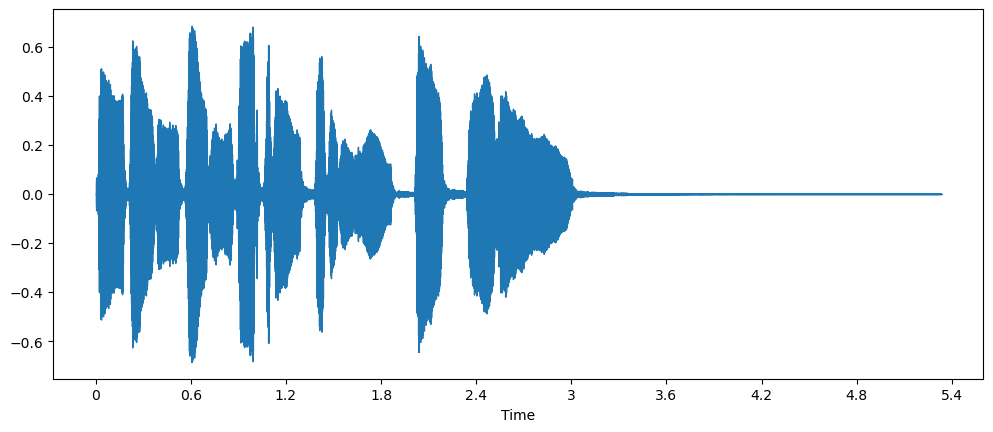

In [6]:
import matplotlib.pyplot as plt
import librosa.display

plt.figure().set_figwidth(12)
librosa.display.waveshow(array, sr=sampling_rate)

librosa returns the audio as floating-point values already, and that the amplitude values are indeed within the [-1.0, 1.0] range.

Another way to visualize audio data is to plot the frequency spectrum of an audio signal, also known as the frequency domain representation. The spectrum is computed using the discrete Fourier transform or DFT. It describes the individual frequencies that make up the signal and how strong they are.

Plot the frequency spectrum for the same trumpet sound by taking the DFT using numpy’s rfft() function. While it is possible to plot the spectrum of the entire sound, it’s more useful to look at a small region instead. Here we’ll take the DFT over the first 4096 samples, which is roughly the length of the first note being played:

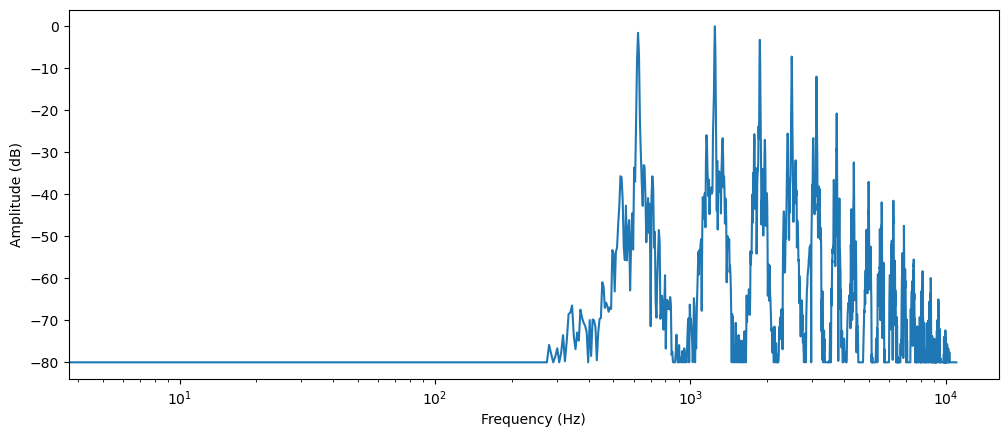

In [7]:
import numpy as np

dft_input = array[:4096]

# calculate the DFT
window = np.hanning(len(dft_input))
windowed_input = dft_input * window
dft = np.fft.rfft(windowed_input) #real and imaginary components

# get the amplitude spectrum in decibels
amplitude = np.abs(dft) #extracts the amplitude information from the spectrogram
amplitude_db = librosa.amplitude_to_db(amplitude, ref=np.max)

# get the frequency bins
frequency = librosa.fft_frequencies(sr=sampling_rate, n_fft=len(dft_input))

plt.figure().set_figwidth(12)
plt.plot(frequency, amplitude_db)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (dB)")
plt.xscale("log")

This plots the strength of the various frequency components that are present in this audio segment. The frequency values are on the x-axis, usually plotted on a logarithmic scale, while their amplitudes are on the y-axis.

The angle between the real and imaginary components provides the so-called phase spectrum, but this is often discarded in machine learning applications.

In practice, people use the term FFT interchangeably with DFT, as the FFT or Fast Fourier Transform is the only efficient way to calculate the DFT on a computer.

The spectrum only shows a frozen snapshot of the frequencies at a given instant. If take multiple DFTs, each covering only a small slice of time, and stack the resulting spectra together into a spectrogram.

A spectrogram plots the frequency content of an audio signal as it changes over time. It allows you to see time, frequency, and amplitude all on one graph. The algorithm that performs this computation is the STFT or Short Time Fourier Transform.

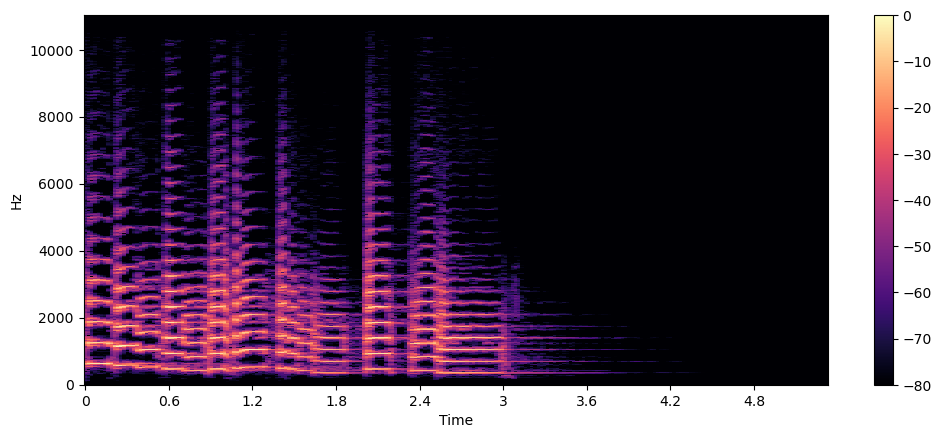

In [8]:
import numpy as np

D = librosa.stft(array)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure().set_figwidth(12)
librosa.display.specshow(S_db, x_axis="time", y_axis="hz")
plt.colorbar()

In this plot, the x-axis represents time as in the waveform visualization but now the y-axis represents frequency in Hz. The intensity of the color gives the amplitude or power of the frequency component at each point in time, measured in decibels (dB).

The spectrogram is created by taking short segments of the audio signal, typically lasting a few milliseconds, and calculating the discrete Fourier transform of each segment to obtain its frequency spectrum. The resulting spectra are then stacked together on the time axis to create the spectrogram. Each vertical slice in this image corresponds to a single frequency spectrum. By default, librosa.stft() splits the audio signal into segments of 2048 samples, which gives a good trade-off between frequency resolution and time resolution.

Since the spectrogram and the waveform are different views of the same data, it’s possible to turn the spectrogram back into the original waveform using the inverse STFT. However, this requires the phase information in addition to the amplitude information. If the spectrogram was generated by a machine learning model, it typically only outputs the amplitudes. In that case, we can use a phase reconstruction algorithm such as the classic Griffin-Lim algorithm, or using a neural network called a vocoder, to reconstruct a waveform from the spectrogram.

# Mel spectrogram

A mel spectrogram is a variation of the spectrogram that is commonly used in speech processing and machine learning tasks. It is similar to a spectrogram in that it shows the frequency content of an audio signal over time, but on a different frequency axis.

In a standard spectrogram, the frequency axis is linear and is measured in hertz (Hz). However, the human auditory system is more sensitive to changes in lower frequencies than higher frequencies, and this sensitivity decreases logarithmically as frequency increases. The mel scale is a perceptual scale that approximates the non-linear frequency response of the human ear.

To create a mel spectrogram, the STFT is used just like before, splitting the audio into short segments to obtain a sequence of frequency spectra. Additionally, each spectrum is sent through a set of filters, the so-called mel filterbank, to transform the frequencies to the mel scale.

Let’s see how we can plot a mel spectrogram using librosa’s melspectrogram() function, which performs all of those steps for us:

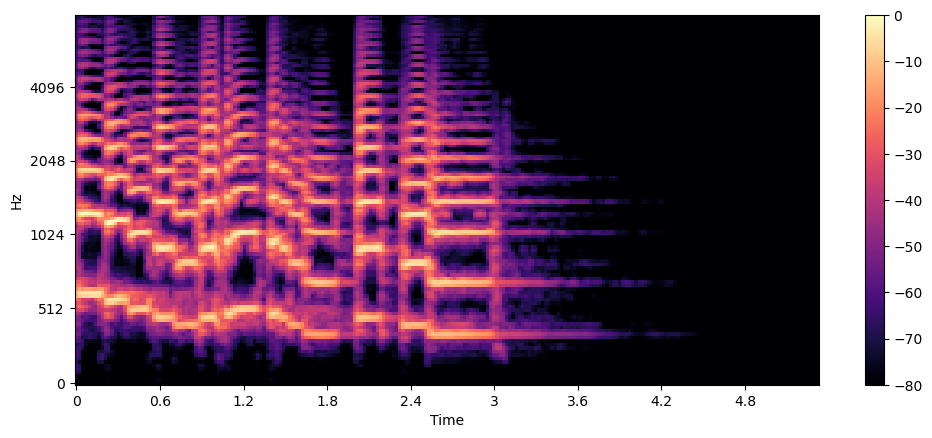

In [9]:
S = librosa.feature.melspectrogram(y=array, sr=sampling_rate, n_mels=128, fmax=8000)
S_dB = librosa.power_to_db(S, ref=np.max) #log-mel spectrogram

plt.figure().set_figwidth(12)
librosa.display.specshow(S_dB, x_axis="time", y_axis="mel", sr=sampling_rate, fmax=8000)
plt.colorbar()

In the example above, n_mels stands for the number of mel bands to generate. The mel bands define a set of frequency ranges that divide the spectrum into perceptually meaningful components, using a set of filters whose shape and spacing are chosen to mimic the way the human ear responds to different frequencies. Common values for n_mels are 40 or 80. fmax indicates the highest frequency (in Hz) we care about.

 Not all mel spectrograms are the same! There are two different mel scales in common use ("htk" and "slaney"), and instead of the power spectrogram the amplitude spectrogram may be used. The conversion to a log-mel spectrogram doesn't always compute true decibels but may simply take the `log`. 

 Creating a mel spectrogram is a lossy operation as it involves filtering the signal. Converting a mel spectrogram back into a waveform is more difficult than doing this for a regular spectrogram, as it requires estimating the frequencies that were thrown away. This is why machine learning models such as HiFiGAN vocoder are needed to produce a waveform from a mel spectrogram.

 Compared to a standard spectrogram, a mel spectrogram can capture more meaningful features of the audio signal for human perception, making it a popular choice in tasks such as speech recognition, speaker identification, and music genre classification.

# Audio Dataset

In [10]:
! pip install datasets[audio]

Audio dataset called MINDS-14 (https://huggingface.co/datasets/PolyAI/minds14), which contains recordings of people asking an e-banking system questions in several languages and dialects.

In [1]:
from datasets import load_dataset
#Australian subset (en-AU) of the data
#en-US, zh-CN
minds = load_dataset("PolyAI/minds14", name="en-AU", split="train")
minds

Dataset({
    features: ['path', 'audio', 'transcription', 'english_transcription', 'intent_class', 'lang_id'],
    num_rows: 654
})

The dataset contains 654 audio files, each of which is accompanied by a transcription, an English translation, and a label indicating the intent behind the person’s query. The audio column contains the raw audio data.

In [2]:
example = minds[0]
example

{'path': '/home/lkk/.cache/huggingface/datasets/downloads/extracted/982a9a59db1777f93fb67e8ae85fd2066e0e4f157408e90dd6b406a675e4ccf1/en-AU~PAY_BILL/response_4.wav',
 'audio': {'path': '/home/lkk/.cache/huggingface/datasets/downloads/extracted/982a9a59db1777f93fb67e8ae85fd2066e0e4f157408e90dd6b406a675e4ccf1/en-AU~PAY_BILL/response_4.wav',
  'array': array([ 0.        ,  0.00024414, -0.00024414, ..., -0.00024414,
          0.00024414,  0.0012207 ]),
  'sampling_rate': 8000},
 'transcription': 'I would like to pay my electricity bill using my card can you please assist',
 'english_transcription': 'I would like to pay my electricity bill using my card can you please assist',
 'intent_class': 13,
 'lang_id': 2}

The audio column contains several features. Here’s what they are:
* path: the path to the audio file (*.wav in this case).
* array: The decoded audio data, represented as a 1-dimensional NumPy array.
* sampling_rate. The sampling rate of the audio file (8,000 Hz in this example).

The intent_class is a classification category of the audio recording. To convert this number into a meaningful string, we can use the int2str() method:

In [3]:
id2label = minds.features["intent_class"].int2str
id2label(example["intent_class"])

'pay_bill'

the lang_id is going to have the same value for all examples, and won’t be useful. The english_transcription will likely duplicate the transcription in this subset, so we can safely remove them.

In [4]:
#remove irrelevant features
columns_to_remove = ["lang_id", "english_transcription"]
minds = minds.remove_columns(columns_to_remove)
minds

Dataset({
    features: ['path', 'audio', 'transcription', 'intent_class'],
    num_rows: 654
})

Install gradio: https://www.gradio.app/guides/quickstart

In [15]:
! pip install gradio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 8.2 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.9/45.9 kB 8.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.7/302.7 kB 17.9 MB/s eta 0:00:0000:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 381.9/381.9 kB 24.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 8.5 MB/s eta 0:00:00:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.9/92.9 kB 7.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.9/80.9 kB 6.2 MB/s eta 0:00:00ta 0:00:01
  Created wheel for ffmpy: filename=ffmpy-0.3.1-py3-none-any.whl size=5580 sha256=ef5249809843286d61baf0c67c0ef7b21bf2a38c9bf8a0af3888e9bf5cddaf3c
  Stored in directory: /home/lkk/.cache/pip/wheels/01/a6/d1/1c0828c304a4283b2c1639a09ad86f83d7c487ef34c6b4a1bf
Successfully built ffmpy
  Attempting uninstall: typing-extensions
    Found existing installation: typin

Error: ImportError: cannot import name 'Doc' from 'typing_extensions' (/home/lkk/miniconda3/envs/mypy310/lib/python3.10/site-packages/typing_extensions.py)

In [18]:
!pip show typing_extensions 

Name: typing_extensions
Version: 4.8.0
Summary: Backported and Experimental Type Hints for Python 3.8+
Home-page: 
Author: 
Author-email: "Guido van Rossum, Jukka Lehtosalo, Łukasz Langa, Michael Lee" <levkivskyi@gmail.com>
License: 
Location: /home/lkk/miniconda3/envs/mypy310/lib/python3.10/site-packages
Requires: 
Required-by: altair, anthropic, asgiref, cattrs, chromadb, fastapi, gradio, gradio_client, huggingface-hub, librosa, onnx, openllm, opentelemetry-sdk, pinecone-client, pydantic, pydantic_core, pytools, qudida, SQLAlchemy, streamlit, torch, typer, typing-inspect, uvicorn


In [5]:
import gradio as gr


def generate_audio():
    example = minds.shuffle()[0]
    audio = example["audio"]
    return (
        audio["sampling_rate"],
        audio["array"],
    ), id2label(example["intent_class"])


with gr.Blocks() as demo:
    with gr.Column():
        for _ in range(4):
            audio, label = generate_audio()
            output = gr.Audio(audio, label=label)

demo.launch(debug=True)

/home/lkk/miniconda3/envs/mypy310/lib/python3.10/site-packages/gradio/processing_utils.py:354: UserWarning: Trying to convert audio automatically from float64 to 16-bit int format.
  warnings.warn(warning.format(data.dtype))


Running on local URL:  http://127.0.0.1:7860

To create a public link, set `share=True` in `launch()`.


Keyboard interruption in main thread... closing server.


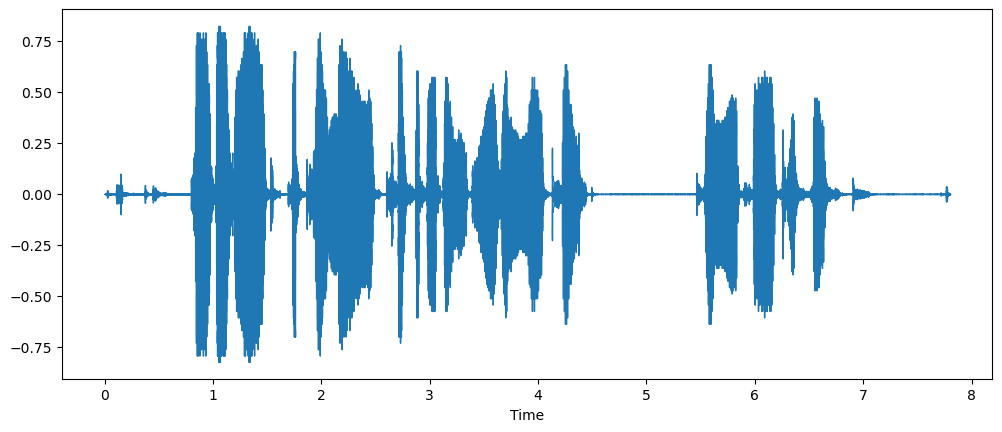

In [6]:
import librosa
import matplotlib.pyplot as plt
import librosa.display

array = example["audio"]["array"]
sampling_rate = example["audio"]["sampling_rate"]

plt.figure().set_figwidth(12)
librosa.display.waveshow(array, sr=sampling_rate)

Resampling the audio data: use cast_column method. MINDS-14 dataset is sampled at 8kHz

In [7]:
from datasets import Audio

minds = minds.cast_column("audio", Audio(sampling_rate=16_000))

In [8]:
minds[0]

{'path': '/home/lkk/.cache/huggingface/datasets/downloads/extracted/982a9a59db1777f93fb67e8ae85fd2066e0e4f157408e90dd6b406a675e4ccf1/en-AU~PAY_BILL/response_4.wav',
 'audio': {'path': '/home/lkk/.cache/huggingface/datasets/downloads/extracted/982a9a59db1777f93fb67e8ae85fd2066e0e4f157408e90dd6b406a675e4ccf1/en-AU~PAY_BILL/response_4.wav',
  'array': array([2.36119668e-05, 1.92324660e-04, 2.19284790e-04, ...,
         9.40907281e-04, 1.16613181e-03, 7.20883254e-04]),
  'sampling_rate': 16000},
 'transcription': 'I would like to pay my electricity bill using my card can you please assist',
 'intent_class': 13}

Filter the data based on some criteria. One of the common cases involves limiting the audio examples to a certain duration. For instance, we might want to filter out any examples longer than 20s to prevent out-of-memory errors when training a model.

In [9]:
MAX_DURATION_IN_SECONDS = 20.0

def is_audio_length_in_range(input_length):
    return input_length < MAX_DURATION_IN_SECONDS #returns True if a sample is shorter than 20s, and False if it is longer than 20s.

In [10]:
# use librosa to get example's duration from the audio file
new_column = [librosa.get_duration(path=x) for x in minds["path"]]
minds = minds.add_column("duration", new_column)

# use 🤗 Datasets' `filter` method to apply the filtering function
minds = minds.filter(is_audio_length_in_range, input_columns=["duration"])

# remove the temporary helper column
minds = minds.remove_columns(["duration"])
minds

Filter:   0%|          | 0/654 [00:00<?, ? examples/s]

Dataset({
    features: ['path', 'audio', 'transcription', 'intent_class'],
    num_rows: 624
})

Pre-processing audio data: Transformers offer a feature extractor class that can convert raw audio data into the input features the model expects.

Whisper is a pre-trained model for automatic speech recognition (ASR) published in September 2022 by Alec Radford et al. from OpenAI.
https://huggingface.co/papers/2212.04356

First, the Whisper feature extractor pads/truncates a batch of audio examples such that all examples have an input length of 30s. Examples shorter than this are padded to 30s by appending zeros to the end of the sequence (zeros in an audio signal correspond to no signal or silence). Examples longer than 30s are truncated to 30s. Since all elements in the batch are padded/truncated to a maximum length in the input space, there is no need for an attention mask. Whisper is unique in this regard, most other audio models require an attention mask that details where sequences have been padded, and thus where they should be ignored in the self-attention mechanism. Whisper is trained to operate without an attention mask and infer directly from the speech signals where to ignore the inputs.

The second operation that the Whisper feature extractor performs is converting the padded audio arrays to log-mel spectrograms. These spectrograms describe how the frequencies of a signal change over time, expressed on the mel scale and measured in decibels (the log part) to make the frequencies and amplitudes more representative of human hearing.

In [11]:
from transformers import WhisperFeatureExtractor

feature_extractor = WhisperFeatureExtractor.from_pretrained("openai/whisper-small")

In [13]:
def prepare_dataset(example):
    audio = example["audio"]
    features = feature_extractor(
        audio["array"], sampling_rate=audio["sampling_rate"], padding=True
    )
    return features

In [14]:
minds = minds.map(prepare_dataset)
minds

Map:   0%|          | 0/624 [00:00<?, ? examples/s]

Dataset({
    features: ['path', 'audio', 'transcription', 'intent_class', 'input_features'],
    num_rows: 624
})

We now have log-mel spectrograms as input_features in the dataset.

In [16]:
import numpy as np

example = minds[0]
input_features = example["input_features"]
print(len(input_features))

1


In [25]:
len(input_features[0])

80

In [24]:
len(input_features[0][0])

780

In [26]:
tmp=np.asarray(input_features[0])

In [27]:
tmp.shape

(80, 780)

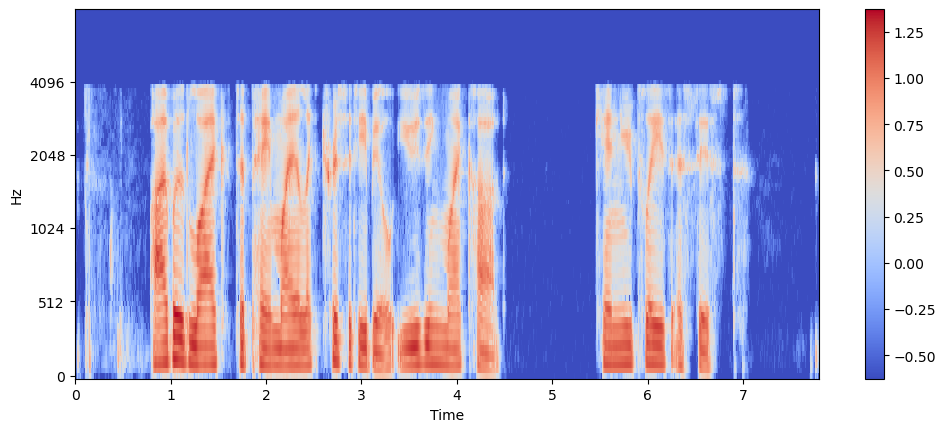

In [17]:
plt.figure().set_figwidth(12)
librosa.display.specshow(
    np.asarray(input_features[0]),
    x_axis="time",
    y_axis="mel",
    sr=feature_extractor.sampling_rate,
    hop_length=feature_extractor.hop_length,
)
plt.colorbar()

You can load the feature extractor and tokenizer for Whisper and other multimodal models separately, or you can load both via a so-called processor. To make things even simpler, use AutoProcessor to load a model’s feature extractor and processor from a checkpoint, like this:

In [28]:
from transformers import AutoProcessor

processor = AutoProcessor.from_pretrained("openai/whisper-small")

In [29]:
minds[0]

{'path': '/home/lkk/.cache/huggingface/datasets/downloads/extracted/982a9a59db1777f93fb67e8ae85fd2066e0e4f157408e90dd6b406a675e4ccf1/en-AU~PAY_BILL/response_4.wav',
 'audio': {'path': None,
  'array': array([0.        , 0.00018311, 0.00021362, ..., 0.00091553, 0.00115967,
         0.0007019 ]),
  'sampling_rate': 16000},
 'transcription': 'I would like to pay my electricity bill using my card can you please assist',
 'intent_class': 13,
 'input_features': [[[-0.6273267269134521,
    -0.4713078737258911,
    0.01015859842300415,
    -0.19987726211547852,
    -0.15121591091156006,
    -0.047553181648254395,
    -0.11007058620452881,
    -0.4246530532836914,
    -0.42451906204223633,
    -0.5951417684555054,
    -0.5256302356719971,
    0.042673587799072266,
    0.14338356256484985,
    0.09881192445755005,
    0.15365523099899292,
    0.40064990520477295,
    0.41676241159439087,
    0.06282097101211548,
    -0.10111141204833984,
    -0.13244080543518066,
    -0.6273267269134521,
    -0.

In [30]:
sample=minds[0]['audio']
sample

{'path': None,
 'array': array([0.        , 0.00018311, 0.00021362, ..., 0.00091553, 0.00115967,
        0.0007019 ]),
 'sampling_rate': 16000}

In [31]:
input_features = processor(sample["array"], sampling_rate=sample["sampling_rate"], return_tensors="pt").input_features 

In [33]:
input_features.shape

torch.Size([1, 80, 3000])

Datasets streaming mode allows us to load the data progressively as we iterate over the dataset. Rather than downloading the whole dataset at once, we load the dataset one example at a time. We iterate over the dataset, loading and preparing examples on the fly when they are needed. 

set streaming=True when you load your dataset

In [35]:
#gigaspeech = load_dataset("speechcolab/gigaspeech", "xs", streaming=True)
mindstream = load_dataset("PolyAI/minds14", name="en-AU", split="train", streaming=True)

In streaming mode,  you can no longer access individual samples using Python indexing (i.e. xxx["train"][sample_idx]). Instead, you have to iterate over the dataset. 

In [36]:
mindstream

In [38]:
next(iter(mindstream))

KeyboardInterrupt: 

In [39]:
mindstream_head = mindstream.take(2)
list(mindstream_head)

KeyboardInterrupt: 

If you’d like to preview several examples from a large dataset, use the take() to get the first n elements. Let’s grab the first two examples in the gigaspeech dataset:

# Model inputs
The input to an audio model can be either text or sound. The goal is to convert this input into an embedding vector that can be processed by the transformer architecture.

## Text input
A text-to-speech model takes text as input. This works just like the original transformer or any other NLP model: The input text is first tokenized, giving a sequence of text tokens. This sequence is sent through an input embedding layer to convert the tokens into 512-dimensional vectors. Those embedding vectors are then passed into the transformer encoder.

## Waveform input
An automatic speech recognition model takes audio as input. To be able to use a transformer for ASR, we first need to convert the audio into a sequence of embedding vectors somehow.

Models such as Wav2Vec2 and HuBERT use the audio waveform directly as the input to the model. A waveform is a one-dimensional sequence of floating-point numbers, where each number represents the sampled amplitude at a given time. This raw waveform is first normalized to zero mean and unit variance, which helps to standardize audio samples across different volumes (amplitudes).

After normalizing, the sequence of audio samples is turned into an embedding using a small convolutional neural network, known as the feature encoder. Each of the convolutional layers in this network processes the input sequence, subsampling the audio to reduce the sequence length, until the final convolutional layer outputs a 512-dimensional vector with the embedding for each 25 ms of audio. Once the input sequence has been transformed into a sequence of such embeddings, the transformer will process the data as usual.

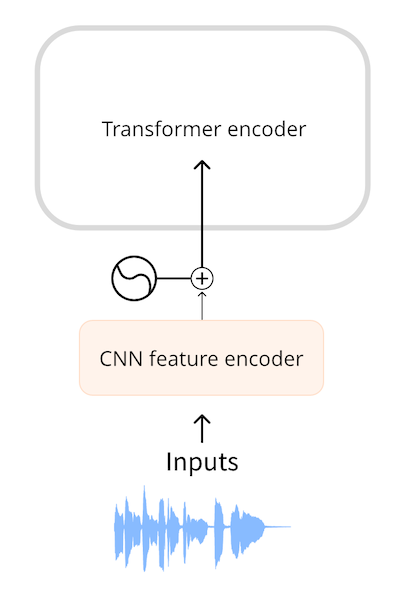

## Spectrogram input

One downside of using the raw waveform as input is that they tend to have long sequence lengths. For example, thirty seconds of audio at a sampling rate of 16 kHz gives an input of length 30 * 16000 = 480000. Longer sequence lengths require more computations in the transformer model, and so higher memory usage.

Because of this, raw audio waveforms are not usually the most efficient form of representing an audio input. By using a spectrogram, we get the same amount of information but in a more compressed form

Models such as Whisper first convert the waveform into a log-mel spectrogram. Whisper always splits the audio into 30-second segments, and the log-mel spectrogram for each segment has shape (80, 3000) where 80 is the number of mel bins and 3000 is the sequence length. By converting to a log-mel spectrogram we’ve reduced the amount of input data, but more importantly, this is a much shorter sequence than the raw waveform. The log-mel spectrogram is then processed by a small CNN into a sequence of embeddings, which goes into the transformer as usual.

In both cases, waveform as well as spectrogram input, there is a small network in front of the transformer that converts the input into embeddings and then the transformer takes over to do its thing.

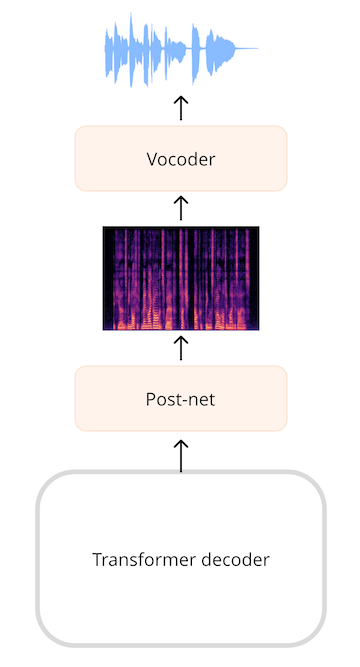

## Model outputs
The transformer architecture outputs a sequence of hidden-state vectors, also known as the output embeddings. Our goal is to transform these vectors into a text or audio output.

## Text output
The goal of an automatic speech recognition model is to predict a sequence of text tokens. This is done by adding a language modeling head — typically a single linear layer — followed by a softmax on top of the transformer’s output. This predicts the probabilities over the text tokens in the vocabulary.

## Spectrogram output
For models that generate audio, such as a text-to-speech (TTS) model, we’ll have to add layers that can produce an audio sequence. It’s very common to generate a spectrogram and then use an additional neural network, known as a vocoder, to turn this spectrogram into a waveform.

In the SpeechT5 TTS model, for example, the output from the transformer network is a sequence of 768-element vectors. A linear layer projects that sequence into a log-mel spectrogram. A so-called post-net, made up of additional linear and convolutional layers, refines the spectrogram by reducing noise. The vocoder then makes the final audio waveform.



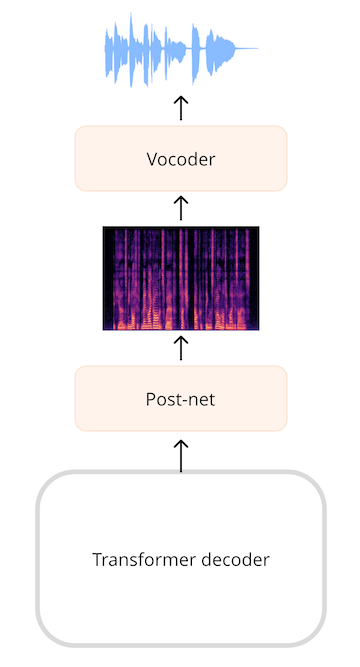

 If you take an existing waveform and apply the Short-Time Fourier Transform or STFT, it is possible to perform the inverse operation, the ISTFT, to get the original waveform again. This works because the spectrogram created by the STFT contains both amplitude and phase information, and both are needed to reconstruct the waveform. However, audio models that generate their output as a spectrogram typically only predict the amplitude information, not the phase. To turn such a spectrogram into a waveform, we have to somehow estimate the phase information. That's what a vocoder does.

Most audio transformer models are more alike than different — they’re all built on the same transformer architecture and attention layers, although some models will only use the encoder portion of the transformer while others use both the encoder and decoder.

You’ve also seen how to get audio data into and out of transformer models. To perform the different audio tasks of ASR, TTS, and so on, we can simply swap out the layers that pre-process the inputs into embeddings, and swap out the layers that post-process the predicted embeddings into outputs, while the transformer backbone stays the same.

# Audio classification
Audio classification involves assigning one or more labels to an audio recording based on its content. The labels could correspond to different sound categories

MINDS-14 contains recordings of people asking an e-banking system questions in several languages and dialects, and has the intent_class for each recording. We can classify the recordings by intent of the call.

In [40]:
from datasets import load_dataset
from datasets import Audio

minds = load_dataset("PolyAI/minds14", name="en-AU", split="train")
minds = minds.cast_column("audio", Audio(sampling_rate=16_000))

To classify an audio recording into a set of classes, we can use the audio-classification pipeline

In [41]:
from transformers import pipeline

classifier = pipeline(
    "audio-classification",
    model="anton-l/xtreme_s_xlsr_300m_minds14",
)

This pipeline expects the audio data as a NumPy array.

In [42]:
example = minds[0]

In [43]:
example["audio"]["array"].shape

(124830,)

In [44]:
classifier(example["audio"]["array"])

[{'score': 0.9625310301780701, 'label': 'pay_bill'},
 {'score': 0.028672747313976288, 'label': 'freeze'},
 {'score': 0.003349797334522009, 'label': 'card_issues'},
 {'score': 0.002005803631618619, 'label': 'abroad'},
 {'score': 0.000848432769998908, 'label': 'high_value_payment'}]

In [45]:
id2label = minds.features["intent_class"].int2str
id2label(example["intent_class"])

'pay_bill'

# Automatic speech recognition (ASR)

In [46]:
from transformers import pipeline

asr = pipeline("automatic-speech-recognition")

No model was supplied, defaulted to facebook/wav2vec2-base-960h and revision 55bb623 (https://huggingface.co/facebook/wav2vec2-base-960h).
Using a pipeline without specifying a model name and revision in production is not recommended.


Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at facebook/wav2vec2-base-960h and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [47]:
example = minds[1]
asr(example["audio"]["array"])

{'text': 'ELL I LIKE TO PAY FOR BILL IM I OUGHT I SHALL LIKE TO MAK  A PAYMENT BUT AM DE COULD JUMP ME OUT'}

In [48]:
example["english_transcription"]

'hello I like to pay for Bill I would actually like to make a payment but yeah could you help me'

# Audio generation
The tasks that we will look into here are speech generation (aka “text-to-speech”) and music generation. In text-to-speech, a model transforms a piece of text into lifelike spoken language sound, opening the door to applications such as virtual assistants, accessibility tools for the visually impaired, and personalized audiobooks. On the other hand, music generation can enable creative expression, and finds its use mostly in entertainment and game development industries.

Bark is a transformer-based text-to-audio model created by Suno. Bark can generate highly realistic, multilingual speech as well as other audio - including music, background noise and simple sound effects. The model can also produce nonverbal communications like laughing, sighing and crying.
https://huggingface.co/suno/bark-small

In [49]:
from transformers import pipeline

pipe = pipeline("text-to-speech", model="suno/bark-small")

In [50]:
text = "Ladybugs have had important roles in culture and religion, being associated with luck, love, fertility and prophecy. "
output = pipe(text)

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:10000 for open-end generation.


In [51]:
from IPython.display import Audio

Audio(output["audio"], rate=output["sampling_rate"])

# Generating music
https://huggingface.co/facebook/musicgen-small

In [52]:
music_pipe = pipeline("text-to-audio", model="facebook/musicgen-small", device=0)

In [64]:
music = music_pipe("Classic guitar music with a soothing melody", forward_params={"do_sample": True, "max_new_tokens": 512})

In [65]:
music

{'audio': array([[[-0.04367604, -0.04348847, -0.0438367 , ...,  0.00636662,
           0.0042454 , -0.00084464]]], dtype=float32),
 'sampling_rate': None}

In [67]:
import scipy
scipy.io.wavfile.write("musicgen_out.wav", rate=32000, data=music["audio"])

In [66]:
Audio(music["audio"][0], rate=32000)

In [69]:
from transformers import AutoProcessor, MusicgenForConditionalGeneration

processor = AutoProcessor.from_pretrained("facebook/musicgen-small")
model = MusicgenForConditionalGeneration.from_pretrained("facebook/musicgen-small")

inputs = processor(
    text=["80s pop track with bassy drums and synth", "90s rock song with loud guitars and heavy drums"],
    padding=True,
    return_tensors="pt",
)

audio_values = model.generate(**inputs, max_new_tokens=256)


In [70]:
audio_values

tensor([[[0.1284, 0.1210, 0.1635,  ..., 0.1540, 0.1251, 0.1492]],

        [[0.0194, 0.0190, 0.0371,  ..., 0.2783, 0.2781, 0.2855]]])

In [73]:
from IPython.display import Audio

sampling_rate = model.config.audio_encoder.sampling_rate
Audio(audio_values[0].numpy(), rate=sampling_rate)


# Transformer for audio

A key feature of transformer models is that they are built with special layers called attention layers. These layers tell the model to pay specific attention to certain elements in the input sequence and ignore others when computing the feature representations.



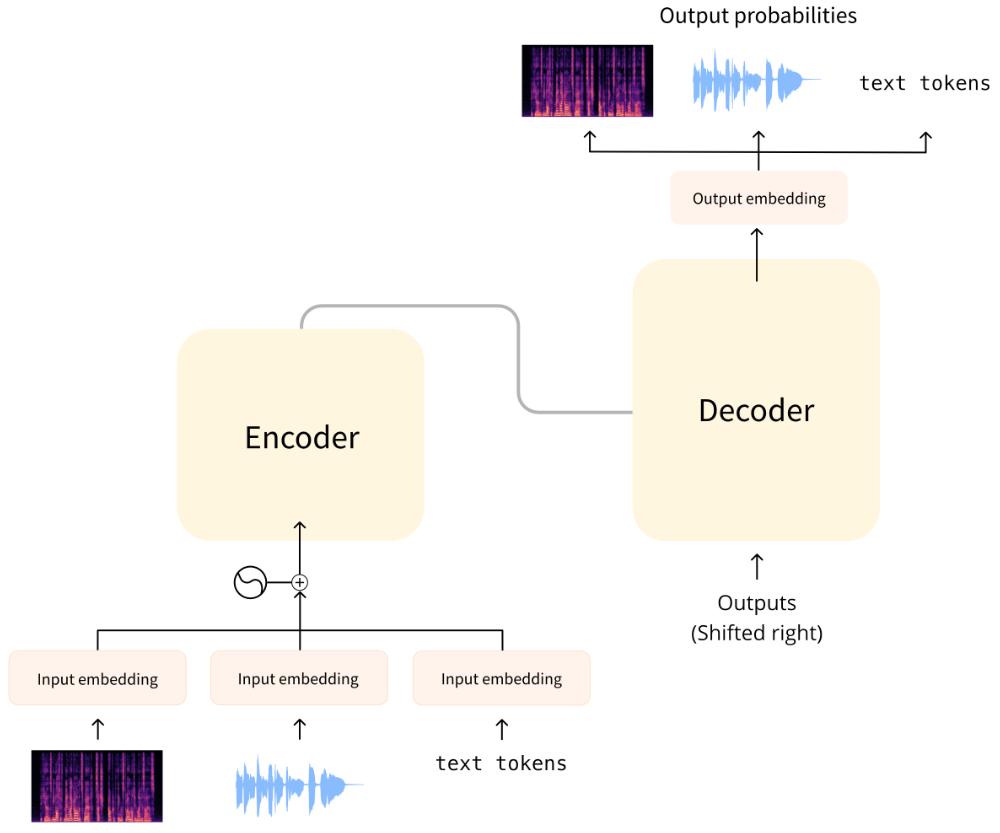

# CTC Architecture - encoder only

CTC or Connectionist Temporal Classification is a technique that is used with encoder-only transformer models for automatic speech recognition. Examples of such models are Wav2Vec2, HuBERT and M-CTC-T.

Automatic speech recognition or ASR involves taking audio as input and producing text as output. We have a few choices for how to predict the text:
* as individual characters
* as phonemes
* as word tokens

An encoder-only transformer is the simplest kind of transformer because it just uses the encoder portion of the model. The encoder reads the input sequence (the audio waveform) and maps this into a sequence of hidden-states, also known as the output embeddings.

With a CTC model, we apply an additional linear mapping on the sequence of hidden-states to get class label predictions. The class labels are the characters of the alphabet (a, b, c, …). This way we’re able to predict any word in the target language with a small classification head, as the vocabulary just needs to exist of 26 characters plus a few special tokens.

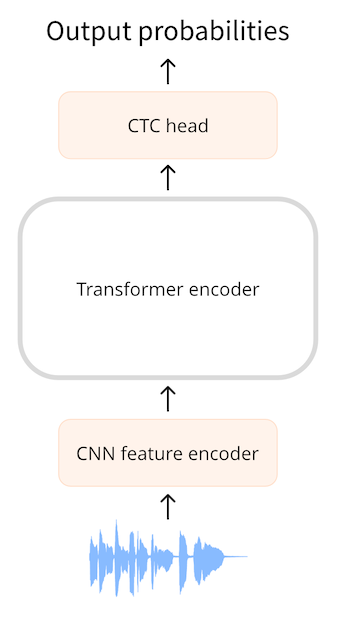

In speech, we don’t know the alignment of the audio inputs and text outputs. We know that the order the speech is spoken in is the same as the order that the text is transcribed in (the alignment is so-called monotonic), but we don’t know how the characters in the transcription line up to the audio. This is where the CTC algorithm comes in.

In NLP models the vocabulary is usually made up of thousands of tokens that describe not just individual characters but parts of words or even complete words. For CTC, however, a small vocabulary works best and we generally try to keep it to less than 50 characters. We don't care about the casing of the letters, so only using uppercase (or only lowercase) is sufficient. Numbers are spelled out, e.g. `"20"` becomes `"twenty"`. In addition to the letters, we need at least a word separator token (space) and a padding token. Just as with an NLP model, the padding token allows us to combine multiple examples in a batch, but it's also the token the model will predict for silences. In English, it's also useful to keep the `'` character — after all, `"it's"` and `"its"` have very different meanings.

An ASR model is trained on a dataset consisting of (audio, text) pairs where the text is a human-made transcription of the audio file. Generally the dataset does not include any timing information that says which word or syllable occurs where in the audio file. Since we can’t rely on timing information during training, we don’t have any idea how the input and output sequences should be aligned.

In Wav2Vec2, the model first downsamples the audio input using the CNN feature encoder to a shorter sequence of hidden-states, where there is one hidden-state vector for every 20 milliseconds of audio. For one second of audio, we then forward a sequence of 50 hidden-states to the transformer encoder. (The audio segments extracted from the input sequence partially overlap, so even though one hidden-state vector is emitted every 20 ms, each hidden-state actually represent 25 ms of audio.)

The transformer encoder predicts one feature representation for each of these hidden-states, meaning we receive a sequence of 50 outputs from the transformer. Each of these outputs has a dimensionality of 768. The output sequence of the transformer encoder in this example therefore has shape (768, 50). As each of these predictions covers 25 ms of time, which is shorter than the duration of a phoneme, it makes sense to predict individual phonemes or characters but not entire words. CTC works best with a small vocabulary, so we’ll predict characters.

To make text predictions, we map each of the 768-dimensional encoder outputs to our character labels using a linear layer (the “CTC head”). The model then predicts a (50, 32) tensor containing the logits, where 32 is the number of tokens in the vocabulary. Since we make one prediction for each of the features in the sequence, we end up with a total of 50 character predictions for each second of audio.

The model needs to output something for every 20 ms of audio in the input sequence, and if a character is spread out over a period longer than 20 ms then it will appear multiple times in the output. There’s no way to avoid this, especially since we don’t know what the timing of the transcript is during training. CTC is a way to filter out these duplicates.

In reality, the predicted sequence also contains a lot of padding tokens for when the model isn’t quite sure what the sound represents, or for the empty space between characters. We removed these padding tokens from the example for clarity. The partial overlap between audio segments is another reason characters get duplicated in the output.

The key to the CTC algorithm is using a special token, often called the blank token. This is just another token that the model will predict and it’s part of the vocabulary. In this example, the blank token is shown as _. This special token serves as a hard boundary between groups of characters.

The | token is the word separator character. In the example we use | instead of a space making it easier to spot where the word breaks are, but it serves the same purpose.

with the CTC blank token we can remove the duplicates in each group, so that:
"_ER_RRR_ORR"->"_ER_R_OR"->"ERROR"

the model predicts one token (character) for every 20 ms of (partially overlapping) audio from the input waveform. This gives a lot of duplicates. Thanks to the CTC blank token, we can easily remove these duplicates without destroying the proper spelling of the words. This is a very simple and convenient way to solve the problem of aligning the output text with the input audio.

In the actual Wav2Vec2 model, the CTC blank token is the same as the padding token ``. The model will predict many of these `` tokens, for example when there isn't a clear character to predict for the current 20 ms of audio. Using the same token for padding as for CTC blanking simplifies the decoding algorithm and it helps keep the vocab small.

Adding CTC to a transformer encoder model is easy: the output sequence from the encoder goes into a linear layer that projects the acoustic features to the vocabulary. The model is trained with a special CTC loss.

One downside of CTC is that it may output words that sound correct, but are not spelled correctly. After all, the CTC head only considers individual characters, not complete words. One way to improve the quality of the audio transcriptions is to use an external language model. This language model essentially acts as a spellchecker on top of the CTC output.

All transformer-based CTC models have a very similar architecture: they use the transformer encoder (but not the decoder) with a CTC head on top. Architecture-wise they are more alike than different.

One difference between Wav2Vec2 and M-CTC-T is that the former works on raw audio waveforms while the latter uses mel spectrograms as input. The models also have been trained for different purposes. M-CTC-T, for example, is trained for multilingual speech recognition, and therefore has a relatively large CTC head that includes Chinese characters in addition to other alphabets.

Wav2Vec2 & HuBERT use the exact same architecture but are trained in very different ways. Wav2Vec2 is pre-trained like BERT’s masked language modeling, by predicting speech units for masked parts of the audio. HuBERT takes the BERT inspiration a step further and learns to predict “discrete speech units”, which are analogous to tokens in a text sentence, so that speech can be treated using established NLP techniques.

# Seq2Seq architecture - encoder-decoder

With encoder-only transformer models, the encoder made a prediction for each element in the input sequence. Therefore, both input and output sequences will always have the same length. In the case of CTC models such as Wav2Vec2 the input waveform was first downsampled, but there still was one prediction for every 20 ms of audio.

With a seq2seq model, there is no such one-to-one correspondence and the input and output sequences can have different lengths. That makes seq2seq models suitable for NLP tasks such as text summarization or translation between different languages — but also for audio tasks such as speech recognition.

The architecture of Whisper:

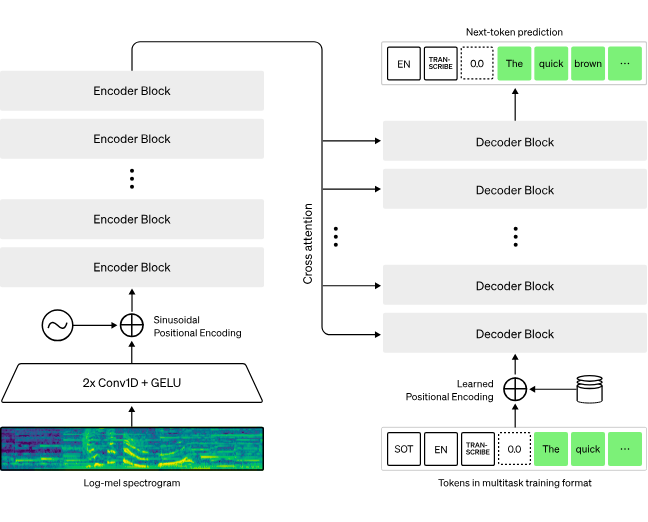

https://huggingface.co/learn/audio-course/chapter3/seq2seq